# Лабораторная работа №4. Сравнительный анализ алгоритмов классификации
# Часть 2. Программа моделирования и оптимизации

## Цель работы

Обучить классические алгоритмы классификации — kNN, дерево решений, SVM и многослойный персептрон (MLP) — на данных, подготовленных в части 1, и автоматически подобрать их ключевые гиперпараметры с помощью кросс-валидации (`GridSearchCV` / `RandomizedSearchCV`).

## 1. Подготовка данных

Повторяем шаги части 1: удаляем `ID`, константный `oral` и дубликаты, делим 80/20 со `stratify` и `random_state=42`. Выборки получаются те же самые, что и в части 1.

In [50]:
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

DATASETS_DIR = Path("../part1/datasets")
MODELS_DIR = Path("./models")
RESULTS_DIR = Path("./results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

In [51]:
def build_preprocessor(X):
    numeric_cols = X.select_dtypes(include="number").columns.tolist()
    categorical_cols = [col for col in X.columns if col not in numeric_cols]

    transformers = [("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols)]
    if categorical_cols:
        transformers.append(("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
        ]), categorical_cols))
    return ColumnTransformer(transformers)


smoking_df = pd.read_csv(DATASETS_DIR / "smoking.csv")
drug_df = pd.read_csv(DATASETS_DIR / "drug200.csv")

smoking_clean = smoking_df.drop(columns=["ID", "oral"]).drop_duplicates().reset_index(drop=True)

SOURCES = {
    "smoking": (smoking_clean.drop(columns="smoking"), smoking_clean["smoking"].astype(int)),
    "drug": (drug_df.drop(columns="Drug"), drug_df["Drug"].astype(str)),
}

DATA = {}
for key, (X, y) in SOURCES.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
    )
    DATA[key] = dict(X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)
    print(f"{key:8s} train = {X_train.shape}, test = {X_test.shape}")

smoking  train = (35641, 24), test = (8911, 24)
drug     train = (160, 5), test = (40, 5)


In [52]:
MODEL_NAMES = {"knn": "kNN", "tree": "Decision Tree", "svm": "SVM", "mlp": "MLP"}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "f1_macro"
N_ITER_MLP = 15
TUNE_SUBSAMPLE = {("smoking", "svm"): 8000}  


def make_pipeline(key, name, **params):
    """Pipeline: препроцессор + классификатор (параметры по умолчанию, если params пуст)."""
    if name == "knn":
        clf = KNeighborsClassifier(**params)
    elif name == "tree":
        clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
    elif name == "svm":
        clf = SVC(random_state=RANDOM_STATE, **params)
    else:
        # MLP: max_iter / early_stopping заданы, чтобы сеть училась за разумное время.
        # На Drug200 (160 объектов) early_stopping отнял бы 10% на валидацию - выключаем.
        small = key == "drug"
        defaults = dict(max_iter=2000 if small else 300, early_stopping=not small,
                        n_iter_no_change=10, random_state=RANDOM_STATE)
        defaults.update(params)
        clf = MLPClassifier(**defaults)
    return Pipeline([("prep", build_preprocessor(DATA[key]["X_train"])), ("clf", clf)])


PARAM_GRIDS = {
    "knn": {
        "clf__n_neighbors": [3, 5, 11, 21, 31],
        "clf__weights": ["uniform", "distance"],
        "clf__p": [1, 2],
    },
    "tree": {
        "clf__criterion": ["gini", "entropy"],
        "clf__max_depth": [3, 5, 7, 10, 15, None],
        "clf__min_samples_leaf": [1, 5, 10, 20],
    },
    "svm": [
        {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10]},
        {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
        {"clf__kernel": ["poly"], "clf__C": [0.1, 1, 10], "clf__degree": [2, 3]},
    ],
    "mlp": {
        "clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
        "clf__activation": ["relu", "tanh"],
        "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
        "clf__learning_rate_init": [1e-3, 3e-3, 1e-2],
    },
}

## 2. Пространство поиска гиперпараметров

In [53]:
rows = []
for name, grid in PARAM_GRIDS.items():
    for g in (grid if isinstance(grid, list) else [grid]):
        rows.append({
            "Модель": MODEL_NAMES[name],
            "Гиперпараметры и значения": "; ".join(f"{k.replace('clf__', '')} ∈ {v}" for k, v in g.items()),
        })
pd.DataFrame(rows)

,Модель,Гиперпараметры и значения
0,kNN,"n_neighbors ∈ [3, 5, 11, 21, 31]; weights ∈ ['uniform', 'distance']; p ∈ [1, 2]"
1,Decision Tree,"criterion ∈ ['gini', 'entropy']; max_depth ∈ [3, 5, 7, 10, 15, None]; min_samples_leaf ∈ [1, 5, 10, 20]"
2,SVM,"kernel ∈ ['linear']; C ∈ [0.1, 1, 10]"
3,SVM,"kernel ∈ ['rbf']; C ∈ [0.1, 1, 10]; gamma ∈ ['scale', 0.01, 0.1]"
4,SVM,"kernel ∈ ['poly']; C ∈ [0.1, 1, 10]; degree ∈ [2, 3]"
5,MLP,"hidden_layer_sizes ∈ [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)]; activation ∈ ['relu', 'tanh']; alpha ∈ [0.0..."


## 3. Вспомогательные функции

In [54]:
def compute_metrics(model, X_test, y_test):
    """Accuracy, Precision/Recall/F1 (macro), F1 (weighted) и ROC-AUC для бинарной задачи."""
    y_pred = model.predict(X_test)
    res = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    }
    if len(model.classes_) == 2:
        res["ROC-AUC"] = roc_auc_score(y_test, model.decision_function(X_test)
                                       if not hasattr(model, "predict_proba") else model.predict_proba(X_test)[:, 1])
    return res


def baseline_table(key):
    """Модели с параметрами по умолчанию: качество на тесте и время обучения."""
    d = DATA[key]
    rows = []
    for name in MODEL_NAMES:
        pipe = make_pipeline(key, name)
        t0 = time.perf_counter()
        pipe.fit(d["X_train"], d["y_train"])
        fit_time = time.perf_counter() - t0
        m = compute_metrics(pipe, d["X_test"], d["y_test"])
        rows.append({"Модель": MODEL_NAMES[name], "Accuracy": m["Accuracy"],
                     "F1 (macro)": m["F1 (macro)"], "Время обучения, с": fit_time})
    return pd.DataFrame(rows).set_index("Модель")


def clean_params(params):
    """{'clf__C': 1} -> {'C': 1}; tuple -> list, numpy -> python (чтобы записать в JSON)."""
    out = {}
    for k, v in params.items():
        v = list(v) if isinstance(v, tuple) else v
        if isinstance(v, np.generic):
            v = v.item()
        out[k.replace("clf__", "")] = v
    return out


def tune(key, name):
    """Подбор гиперпараметров. Возвращает (search, final_model, время поиска, время обучения)."""
    d = DATA[key]
    n = TUNE_SUBSAMPLE.get((key, name))
    if n is None:
        X_s, y_s = d["X_train"], d["y_train"]
    else:
        X_s, _, y_s, _ = train_test_split(d["X_train"], d["y_train"], train_size=n,
                                          stratify=d["y_train"], random_state=RANDOM_STATE)

    pipe = make_pipeline(key, name)
    if name == "mlp":
        search = RandomizedSearchCV(pipe, PARAM_GRIDS[name], n_iter=N_ITER_MLP, cv=CV,
                                    scoring=SCORING, n_jobs=-1, random_state=RANDOM_STATE)
    else:
        search = GridSearchCV(pipe, PARAM_GRIDS[name], cv=CV, scoring=SCORING, n_jobs=-1)

    t0 = time.perf_counter()
    search.fit(X_s, y_s)
    search_time = time.perf_counter() - t0

    final = clone(search.best_estimator_)
    t0 = time.perf_counter()
    final.fit(d["X_train"], d["y_train"])
    return search, final, search_time, time.perf_counter() - t0


def run_tuning(key):
    searches, finals, rows = {}, {}, []
    for name in MODEL_NAMES:
        search, final, s_time, _ = tune(key, name)
        searches[name], finals[name] = search, final
        rows.append({
            "Модель": MODEL_NAMES[name],
            "Метод": "RandomizedSearchCV" if name == "mlp" else "GridSearchCV",
            "Комбинаций": len(search.cv_results_["params"]),
            "Объектов в поиске": TUNE_SUBSAMPLE.get((key, name)) or len(DATA[key]["X_train"]),
            "Лучший CV F1 (macro)": search.best_score_,
            "Время поиска, с": s_time,
            "Лучшие параметры": clean_params(search.best_params_),
        })
        print(f"[{key}] {MODEL_NAMES[name]:14s} CV F1 = {search.best_score_:.4f}   поиск {s_time:6.1f} с")
    return searches, finals, pd.DataFrame(rows).set_index("Модель")


def top_k(search, k=5):
    df = pd.DataFrame(search.cv_results_)
    cols = [c for c in df.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_fit_time"]
    df = df.sort_values("rank_test_score").head(k)[cols]
    df.columns = [c.replace("param_clf__", "") for c in df.columns]
    return df.dropna(axis=1, how="all").reset_index(drop=True)


def effect(ax, search, x, hue, title, numeric=True):
    """Лучший CV-скор в зависимости от гиперпараметра x (по остальным берём максимум)."""
    df = pd.DataFrame(search.cv_results_)
    df = df.rename(columns={f"param_clf__{x}": x, f"param_clf__{hue}": hue})
    df[x], df[hue] = df[x].astype(str), df[hue].astype(str)
    g = df.groupby([x, hue], sort=False)["mean_test_score"].max().unstack(hue)
    if numeric:
        g = g.loc[sorted(g.index, key=lambda v: float(v) if v != "None" else 1e9)]
    else:
        g = g.sort_index()
    g.plot(ax=ax, marker="o")
    ax.set_title(title)
    ax.set_ylabel("CV F1 (macro)")
    ax.legend(title=hue, fontsize=8)


def plot_effects(searches, title):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    effect(axes[0, 0], searches["knn"], "n_neighbors", "weights", "kNN: число соседей")
    effect(axes[0, 1], searches["tree"], "max_depth", "criterion", "Decision Tree: глубина дерева")
    effect(axes[1, 0], searches["svm"], "C", "kernel", "SVM: параметр C и ядро")
    effect(axes[1, 1], searches["mlp"], "hidden_layer_sizes", "activation",
           "MLP: архитектура и активация (случайный поиск)", numeric=False)
    axes[1, 1].tick_params(axis="x", rotation=20)
    plt.suptitle(title, y=1.01, fontsize=13)
    plt.tight_layout()
    plt.show()

## 4. Датасет Smoking

Бинарная классификация на 35 641 обучающем объекте. Для MLP в базовой конфигурации добавлены только `max_iter=300` и `early_stopping=True` — без них сеть учится слишком долго.

### 4.1. Базовые модели (параметры по умолчанию)

In [55]:
base_smoking = baseline_table("smoking")
base_smoking.style.format({"Accuracy": "{:.4f}", "F1 (macro)": "{:.4f}", "Время обучения, с": "{:.2f}"})

,Accuracy,F1 (macro),"Время обучения, с"
Модель,,,
kNN,0.7047,0.6801,0.15
Decision Tree,0.6877,0.6631,0.79
SVM,0.7639,0.7511,27.17
MLP,0.7646,0.7486,1.46


### 4.2. Подбор гиперпараметров

In [56]:
searches_smoking, finals_smoking, summary_smoking = run_tuning("smoking")

[smoking] kNN            CV F1 = 0.7125   поиск   38.1 с
[smoking] Decision Tree  CV F1 = 0.7222   поиск   12.2 с
[smoking] SVM            CV F1 = 0.7330   поиск   28.4 с
[smoking] MLP            CV F1 = 0.7427   поиск   52.5 с


### 4.3. Лучшие комбинации параметров

In [62]:
summary_smoking.drop(columns="Лучшие параметры").style.format({"Лучший CV F1 (macro)": "{:.4f}", "Время поиска, с": "{:.1f}"})

,Метод,Комбинаций,Объектов в поиске,Лучший CV F1 (macro),"Время поиска, с"
Модель,,,,,
kNN,GridSearchCV,20,35641,0.7125,38.1
Decision Tree,GridSearchCV,48,35641,0.7222,12.2
SVM,GridSearchCV,18,8000,0.7330,28.4
MLP,RandomizedSearchCV,15,35641,0.7427,52.5


In [63]:
for model, params in summary_smoking["Лучшие параметры"].items():
    print(f"{model:14s} {params}")

kNN            {'n_neighbors': 31, 'p': 1, 'weights': 'uniform'}
Decision Tree  {'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 20}
SVM            {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
MLP            {'learning_rate_init': 0.003, 'hidden_layer_sizes': [128, 64, 32], 'alpha': 0.0001, 'activation': 'tanh'}


### 4.4. Влияние гиперпараметров на качество

Для каждого значения гиперпараметра показан лучший результат кросс-валидации по остальным параметрам.

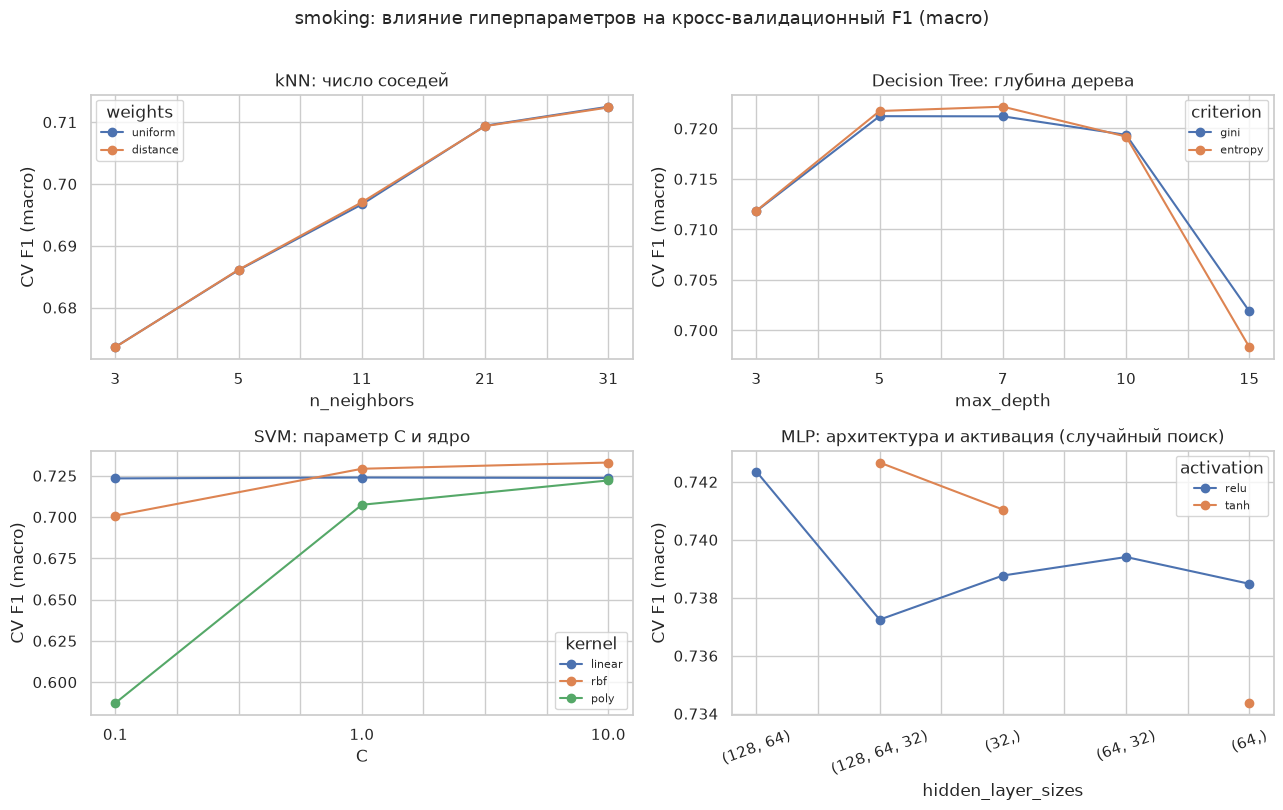

In [64]:
plot_effects(searches_smoking, "smoking: влияние гиперпараметров на кросс-валидационный F1 (macro)")

### 4.5. Топ-5 комбинаций для каждой модели

In [65]:
for name in MODEL_NAMES:
    print(f"=== {MODEL_NAMES[name]} ===")
    display(top_k(searches_smoking[name]))

=== kNN ===


,n_neighbors,p,weights,mean_test_score,std_test_score,mean_fit_time
0,31,1,uniform,0.712495,0.003386,0.151585
1,31,1,distance,0.712371,0.003110,0.143940
2,21,1,uniform,0.709422,0.004651,0.126906
3,21,1,distance,0.709355,0.004702,0.127869
4,31,2,uniform,0.706535,0.004988,0.109791


=== Decision Tree ===


,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time
0,entropy,7,20,0.722158,0.005735,0.519300
1,entropy,7,10,0.722031,0.006204,0.467676
2,entropy,5,20,0.721731,0.001667,0.474534
3,entropy,5,10,0.721730,0.001666,0.475077
4,entropy,5,5,0.721704,0.001652,0.453540


=== SVM ===


,C,kernel,gamma,mean_test_score,std_test_score,mean_fit_time
0,10.0,rbf,0.01,0.732998,0.009360,2.266447
1,1.0,rbf,0.01,0.729224,0.007332,1.933090
2,1.0,rbf,scale,0.726808,0.006645,2.056087
3,1.0,linear,NaN,0.723937,0.012914,3.777379
4,10.0,linear,NaN,0.723655,0.012304,11.781506


=== MLP ===


,learning_rate_init,hidden_layer_sizes,alpha,activation,mean_test_score,std_test_score,mean_fit_time
0,0.003,"(128, 64, 32)",0.0001,tanh,0.742665,0.005826,13.470324
1,0.010,"(128, 64)",0.0001,relu,0.742353,0.007180,7.197640
2,0.003,"(128, 64)",0.1000,relu,0.742005,0.009504,9.625853
3,0.010,"(128, 64)",0.0010,relu,0.741772,0.004639,8.128098
4,0.003,"(128, 64)",0.0100,relu,0.741212,0.003154,8.674580


### 4.6. Сохранение моделей и результатов

In [66]:
for name, model in finals_smoking.items():
    joblib.dump(model, MODELS_DIR / f"smoking_{name}.joblib", compress=3)

base_smoking.to_csv(RESULTS_DIR / "baseline_smoking.csv")
summary_smoking.assign(**{"Лучшие параметры": summary_smoking["Лучшие параметры"].astype(str)}).to_csv(RESULTS_DIR / "search_smoking.csv")
print("Модели smoking сохранены в", MODELS_DIR.resolve())

Модели smoking сохранены в /home/cintie/Projects/uniq/dp2/labs/lab4/part2/models


## 5. Датасет Drug200

Многоклассовая классификация на 160 обучающих объектах — всё считается за секунды. Для MLP отключён `early_stopping` (на валидацию ушло бы всего 16 объектов) и увеличен `max_iter=2000`.

### 6.1. Базовые модели (параметры по умолчанию)

In [67]:
base_drug = baseline_table("drug")
base_drug.style.format({"Accuracy": "{:.4f}", "F1 (macro)": "{:.4f}", "Время обучения, с": "{:.2f}"})

,Accuracy,F1 (macro),"Время обучения, с"
Модель,,,
kNN,0.8500,0.8027,0.01
Decision Tree,0.9750,0.9851,0.01
SVM,1.0000,1.0000,0.01
MLP,1.0000,1.0000,0.25


### 5.2. Подбор гиперпараметров

In [68]:
searches_drug, finals_drug, summary_drug = run_tuning("drug")

[drug] kNN            CV F1 = 0.9111   поиск    0.4 с
[drug] Decision Tree  CV F1 = 0.9810   поиск    0.9 с
[drug] SVM            CV F1 = 0.9600   поиск    0.3 с
[drug] MLP            CV F1 = 0.9592   поиск    2.4 с


### 5.3. Лучшие комбинации параметров

In [69]:
summary_drug.drop(columns="Лучшие параметры").style.format({"Лучший CV F1 (macro)": "{:.4f}", "Время поиска, с": "{:.1f}"})

,Метод,Комбинаций,Объектов в поиске,Лучший CV F1 (macro),"Время поиска, с"
Модель,,,,,
kNN,GridSearchCV,20,160,0.9111,0.4
Decision Tree,GridSearchCV,48,160,0.9810,0.9
SVM,GridSearchCV,18,160,0.9600,0.3
MLP,RandomizedSearchCV,15,160,0.9592,2.4


In [70]:
for model, params in summary_drug["Лучшие параметры"].items():
    print(f"{model:14s} {params}")

kNN            {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
Decision Tree  {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1}
SVM            {'C': 10, 'kernel': 'linear'}
MLP            {'learning_rate_init': 0.003, 'hidden_layer_sizes': [128, 64, 32], 'alpha': 0.0001, 'activation': 'tanh'}


### 5.4. Влияние гиперпараметров на качество

Для каждого значения гиперпараметра показан лучший результат кросс-валидации по остальным параметрам.

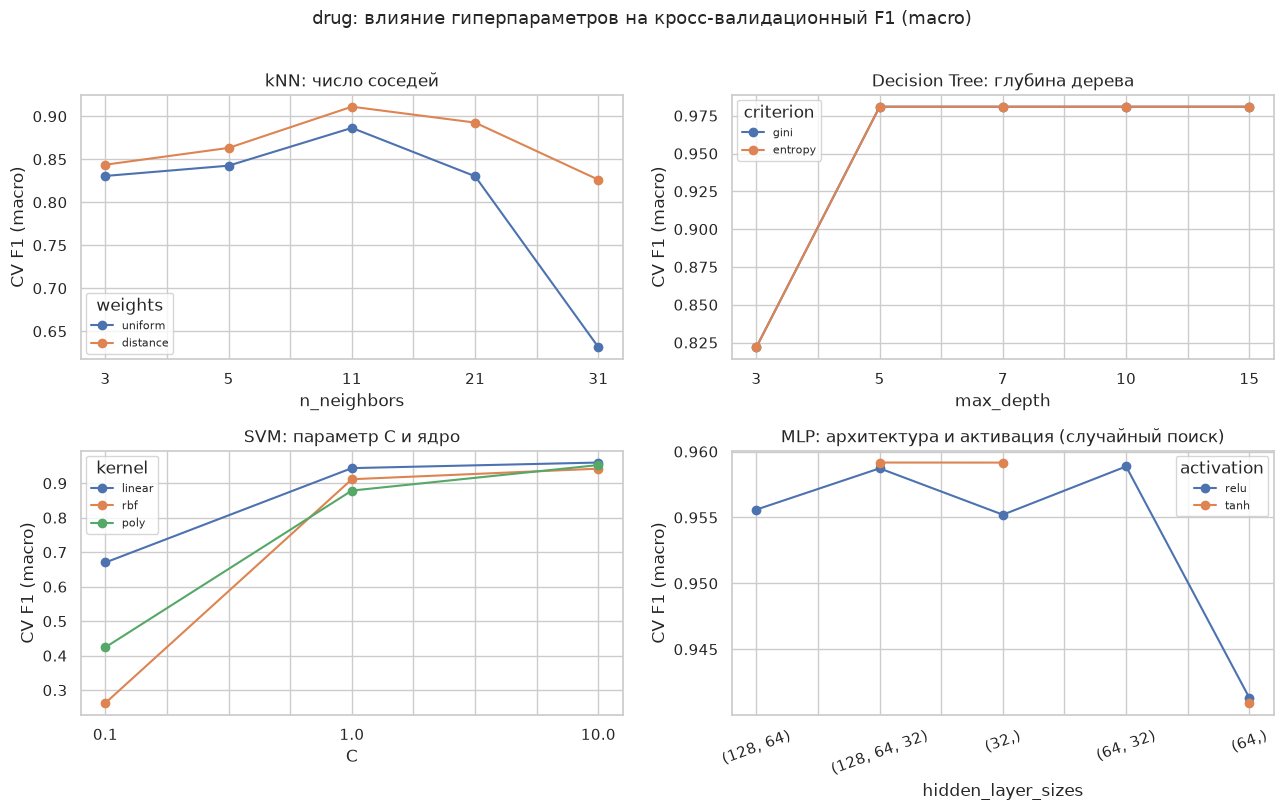

In [71]:
plot_effects(searches_drug, "drug: влияние гиперпараметров на кросс-валидационный F1 (macro)")

### 5.5. Топ-5 комбинаций для каждой модели

In [72]:
for name in MODEL_NAMES:
    print(f"=== {MODEL_NAMES[name]} ===")
    display(top_k(searches_drug[name]))

=== kNN ===


,n_neighbors,p,weights,mean_test_score,std_test_score,mean_fit_time
0,11,1,distance,0.911135,0.072870,0.019682
1,21,1,distance,0.892629,0.044565,0.020277
2,11,1,uniform,0.886465,0.065135,0.020677
3,21,2,distance,0.864820,0.091676,0.020113
4,11,2,distance,0.864207,0.102924,0.019518


=== Decision Tree ===


,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,mean_fit_time
0,gini,5,5,0.980952,0.038095,0.018904
1,gini,5,10,0.980952,0.038095,0.018945
2,gini,5,1,0.980952,0.038095,0.015294
3,gini,10,10,0.980952,0.038095,0.021049
4,gini,10,1,0.980952,0.038095,0.014759


=== SVM ===


,C,kernel,gamma,degree,mean_test_score,std_test_score,mean_fit_time
0,10.0,linear,NaN,NaN,0.960026,0.059507,0.017815
1,10.0,poly,NaN,3.0,0.952701,0.054918,0.019428
2,10.0,poly,NaN,2.0,0.951290,0.041826,0.021819
3,1.0,linear,NaN,NaN,0.943868,0.036389,0.019706
4,10.0,rbf,0.1,NaN,0.942267,0.043561,0.020359


=== MLP ===


,learning_rate_init,hidden_layer_sizes,alpha,activation,mean_test_score,std_test_score,mean_fit_time
0,0.003,"(128, 64, 32)",0.0001,tanh,0.959167,0.081667,0.482745
1,0.010,"(128, 64, 32)",0.0010,tanh,0.959167,0.081667,0.193793
2,0.010,"(32,)",0.1000,tanh,0.959163,0.048649,0.209796
3,0.001,"(64, 32)",0.0100,relu,0.958870,0.056024,0.326148
4,0.010,"(128, 64, 32)",0.0100,relu,0.958727,0.033657,0.091074


### 5.6. Сохранение моделей и результатов

In [73]:
for name, model in finals_drug.items():
    joblib.dump(model, MODELS_DIR / f"drug_{name}.joblib", compress=3)

base_drug.to_csv(RESULTS_DIR / "baseline_drug.csv")
summary_drug.assign(**{"Лучшие параметры": summary_drug["Лучшие параметры"].astype(str)}).to_csv(RESULTS_DIR / "search_drug.csv")
print("Модели drug сохранены в", MODELS_DIR.resolve())

Модели drug сохранены в /home/cintie/Projects/uniq/dp2/labs/lab4/part2/models


## 6. Лучшие гиперпараметры в JSON

Файл `results/best_params.json` читает Streamlit-приложение (кнопка «Подставить лучшие параметры»).

In [78]:
best = {
    "smoking": {n: clean_params(s.best_params_) for n, s in searches_smoking.items()},
    "drug": {n: clean_params(s.best_params_) for n, s in searches_drug.items()},
}
(RESULTS_DIR / "best_params.json").write_text(json.dumps(best, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(best, indent=2, ensure_ascii=False)[:600], "...")

{
  "smoking": {
    "knn": {
      "n_neighbors": 31,
      "p": 1,
      "weights": "uniform"
    },
    "tree": {
      "criterion": "entropy",
      "max_depth": 7,
      "min_samples_leaf": 20
    },
    "svm": {
      "C": 10,
      "gamma": 0.01,
      "kernel": "rbf"
    },
    "mlp": {
      "learning_rate_init": 0.003,
      "hidden_layer_sizes": [
        128,
        64,
        32
      ],
      "alpha": 0.0001,
      "activation": "tanh"
    }
  },
  "drug": {
    "knn": {
      "n_neighbors": 11,
      "p": 1,
      "weights": "distance"
    },
    "tree": {
      "criterion": " ...


## 6. Сравниваем базовые и подобранные модели

Файл `results/best_params.json` читает Streamlit-приложение (кнопка «Подставить лучшие параметры»).

In [80]:
rows = []
for key, base, finals in [("smoking", base_smoking, finals_smoking), ("drug", base_drug, finals_drug)]:
    d = DATA[key]
    for name, model in finals.items():
        m = compute_metrics(model, d["X_test"], d["y_test"])
        b = base.loc[MODEL_NAMES[name]]
        rows.append({
            "Датасет": key, "Модель": MODEL_NAMES[name],
            "Accuracy (базовая)": b["Accuracy"], "Accuracy (подбор)": m["Accuracy"],
            "F1 macro (базовая)": b["F1 (macro)"], "F1 macro (подбор)": m["F1 (macro)"],
        })
effect_df = pd.DataFrame(rows).set_index(["Датасет", "Модель"])
effect_df["Δ F1 macro"] = effect_df["F1 macro (подбор)"] - effect_df["F1 macro (базовая)"]
effect_df.style.format("{:.4f}").background_gradient(subset=["Δ F1 macro"], cmap="RdYlGn", vmin=-0.05, vmax=0.05)

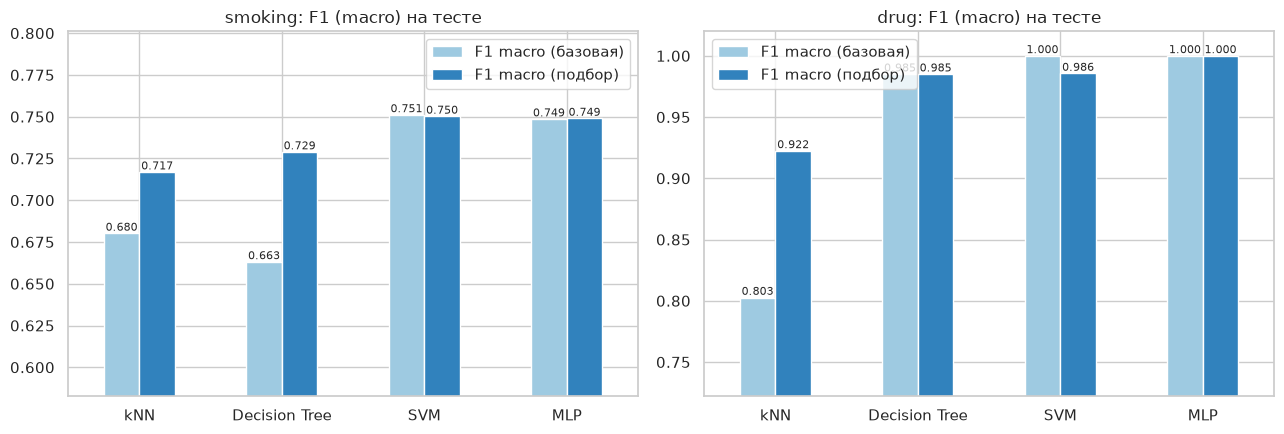

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key in zip(axes, ["smoking", "drug"]):
    sub = effect_df.loc[key][["F1 macro (базовая)", "F1 macro (подбор)"]]
    sub.plot.bar(ax=ax, color=["#9ecae1", "#3182bd"], rot=0)
    ax.set_title(f"{key}: F1 (macro) на тесте")
    ax.set_ylim(sub.min().min() - 0.08, 1.02 if key == "drug" else sub.max().max() + 0.05)
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()